In [3]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [4]:
import os
for item in os.listdir('/content/drive/MyDrive/'):
    print(item)


Reborn and.txt
IMG-20221016-WA0009.jpg
Books
Untitled presentation (1).gslides
Untitled presentation.gslides
Untitled spreadsheet.gsheet
how to align image and text using html in notepad.gsheet
solve it in probability.gsheet
FB_IMG_1724964236875.jpg
Assignment 2 LA.pdf
IMG_20241105_160134_096.jpg
IMG_20241204_145053_246.jpg
IMG_20241204_145054_228.jpg
Colab Notebooks
FeeVoucher_copy.pdf
FeeVoucher_copy 6th.pdf
solve (1).gsheet
solve.gsheet
Usama Zafar_CV.docx
I am sharing 'Usama_Zafar_CV.docx' with you from WPS Office
I'll analyze the provided assignment documents to....gsheet
Usama_B23S0292AI015_Ai Lab 6
BrainMri dataset.zip


In [5]:
import zipfile, os

zip_path = '/content/drive/MyDrive/BrainMri dataset.zip'
extract_path = '/content/BrainMRI/'

os.makedirs(extract_path, exist_ok=True)

print("Unzipping... please wait (may take 2-3 minutes)")
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)
print("Done! Dataset ready.")

Unzipping... please wait (may take 2-3 minutes)
Done! Dataset ready.


In [6]:
import os
for item in os.listdir('/content/BrainMRI/'):
    print(item)

lgg-mri-segmentation
kaggle_3m


In [9]:
#Cell 2 — Install Libraries
!pip install segmentation-models-pytorch albumentations -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.5 MB/s eta 0:00:00


In [10]:
#Cell 3 — Imports
import os, random, cv2, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import jaccard_score, f1_score, roc_auc_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


In [11]:
#Cell 4 — Load Image & Mask Paths
data_root = Path("/content/BrainMRI/kaggle_3m")

images, masks = [], []

for patient_folder in sorted(data_root.iterdir()):
    if not patient_folder.is_dir():
        continue
    for f in sorted(patient_folder.iterdir()):
        if f.suffix in ['.tif', '.png', '.jpg'] and '_mask' not in f.name:
            mask_path = f.parent / (f.stem + '_mask' + f.suffix)
            if mask_path.exists():
                images.append(str(f))
                masks.append(str(mask_path))

print(f"Total image-mask pairs found: {len(images)}")

train_imgs, test_imgs, train_masks, test_masks = train_test_split(
    images, masks, test_size=0.2, random_state=SEED)
train_imgs, val_imgs, train_masks, val_masks = train_test_split(
    train_imgs, train_masks, test_size=0.15, random_state=SEED)

print(f"Train: {len(train_imgs)} | Val: {len(val_imgs)} | Test: {len(test_imgs)}")

Total image-mask pairs found: 3929
Train: 2671 | Val: 472 | Test: 786


In [12]:
#Cell 5 — Dataset Class
IMG_SIZE = 256

train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=30, p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.GaussNoise(p=0.2),
    A.Normalize(mean=[0.485], std=[0.229]),
    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=[0.485], std=[0.229]),
    ToTensorV2()
])

class BrainMRIDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths  = mask_paths
        self.transform   = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img  = cv2.imread(self.image_paths[idx], cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(self.mask_paths[idx],  cv2.IMREAD_GRAYSCALE)

        img  = img.astype(np.float32)
        mask = (mask > 127).astype(np.float32)

        if self.transform:
            aug  = self.transform(image=img, mask=mask)
            img  = aug['image']
            mask = aug['mask'].unsqueeze(0)

        return img, mask

train_ds = BrainMRIDataset(train_imgs, train_masks, train_transform)
val_ds   = BrainMRIDataset(val_imgs,   val_masks,   val_transform)
test_ds  = BrainMRIDataset(test_imgs,  test_masks,  val_transform)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=16, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

print("Dataloaders ready!")

Dataloaders ready!


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [14]:
#Cell 7 — Loss, Optimizer, Scheduler
class ComboBCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, smooth=1e-6):
        super().__init__()
        self.bce_weight = bce_weight
        self.bce   = nn.BCEWithLogitsLoss()
        self.smooth = smooth

    def dice_loss(self, logits, targets):
        probs = torch.sigmoid(logits)
        num   = 2 * (probs * targets).sum(dim=(2,3)) + self.smooth
        den   = probs.sum(dim=(2,3)) + targets.sum(dim=(2,3)) + self.smooth
        return 1 - (num / den).mean()

    def forward(self, logits, targets):
        return (self.bce_weight * self.bce(logits, targets) +
                (1 - self.bce_weight) * self.dice_loss(logits, targets))

criterion = ComboBCEDiceLoss(bce_weight=0.5)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=40)
scaler    = torch.cuda.amp.GradScaler()

print("Loss, optimizer, scheduler ready!")

Loss, optimizer, scheduler ready!


/tmp/ipykernel_1104/772073817.py:22: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler()


In [15]:
#Cell 8 — Training Loop
EPOCHS   = 40
best_dice = 0.0
history  = {"train_loss":[], "val_loss":[], "val_dice":[], "val_iou":[], "val_auc":[]}

os.makedirs("/content/outputs", exist_ok=True)

def train_epoch(model, loader):
    model.train()
    total = 0
    for imgs, masks in loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            loss = criterion(model(imgs), masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item()
    return total / len(loader)

@torch.no_grad()
def eval_epoch(model, loader):
    model.eval()
    total, all_p, all_t = 0, [], []
    for imgs, masks in loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        logits = model(imgs)
        total += criterion(logits, masks).item()
        probs  = torch.sigmoid(logits).cpu().numpy().flatten()
        tgts   = masks.cpu().numpy().flatten().astype(int)
        all_p.append(probs)
        all_t.append(tgts)
    p = np.concatenate(all_p)
    t = np.concatenate(all_t)
    bp = (p > 0.5).astype(int)
    dice = f1_score(t, bp, zero_division=0)
    iou  = jaccard_score(t, bp, zero_division=0)
    try:    auc = roc_auc_score(t, p)
    except: auc = 0.0
    return total/len(loader), dice, iou, auc

print("Starting training...")
for epoch in range(1, EPOCHS+1):
    tr_loss = train_epoch(model, train_loader)
    vl_loss, vl_dice, vl_iou, vl_auc = eval_epoch(model, val_loader)
    scheduler.step()

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(vl_loss)
    history["val_dice"].append(vl_dice)
    history["val_iou"].append(vl_iou)
    history["val_auc"].append(vl_auc)

    flag = ""
    if vl_dice > best_dice:
        best_dice = vl_dice
        torch.save(model.state_dict(), "/content/outputs/best_model.pth")
        flag = "  ← BEST SAVED"

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:2d}/{EPOCHS}]  "
              f"Train Loss: {tr_loss:.4f}  "
              f"Val Loss: {vl_loss:.4f}  "
              f"Dice: {vl_dice:.4f}  "
              f"IoU: {vl_iou:.4f}  "
              f"AUC: {vl_auc:.4f}{flag}")

print(f"\nTraining complete! Best Val Dice: {best_dice:.4f}")

Starting training...


/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [ 1/40]  Train Loss: 0.5581  Val Loss: 0.5014  Dice: 0.1983  IoU: 0.1100  AUC: 0.8874  ← BEST SAVED


/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [ 5/40]  Train Loss: 0.4741  Val Loss: 0.4377  Dice: 0.4613  IoU: 0.2998  AUC: 0.9388  ← BEST SAVED


...

Epoch [30/40]  Train Loss: 0.4355  Val Loss: 0.3674  Dice: 0.7786  IoU: 0.6375  AUC: 0.9962


/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [35/40]  Train Loss: 0.4383  Val Loss: 0.3622  Dice: 0.8405  IoU: 0.7249  AUC: 0.9972  ← BEST SAVED


/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1104/2093935550.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [40/40]  Train Loss: 0.4363  Val Loss: 0.3610  Dice: 0.8365  IoU: 0.7189  AUC: 0.9973

Training complete! Best Val Dice: 0.8405


In [16]:
#Cell 9 — Test Evaluation
model.load_state_dict(torch.load("/content/outputs/best_model.pth"))
test_loss, test_dice, test_iou, test_auc = eval_epoch(model, test_loader)

print("="*50)
print("       FINAL TEST RESULTS")
print("="*50)
print(f"  Dice Score : {test_dice:.4f}")
print(f"  IoU Score  : {test_iou:.4f}")
print(f"  AUC-ROC    : {test_auc:.4f}")
print(f"  Test Loss  : {test_loss:.4f}")
print("="*50)

with open("/content/outputs/results.txt", "w") as f:
    f.write(f"Dice Score : {test_dice:.4f}\n")
    f.write(f"IoU Score  : {test_iou:.4f}\n")
    f.write(f"AUC-ROC    : {test_auc:.4f}\n")
    f.write(f"Test Loss  : {test_loss:.4f}\n")
print("Results saved!")

       FINAL TEST RESULTS
  Dice Score : 0.7792
  IoU Score  : 0.6382
  AUC-ROC    : 0.9958
  Test Loss  : 0.3863
Results saved!


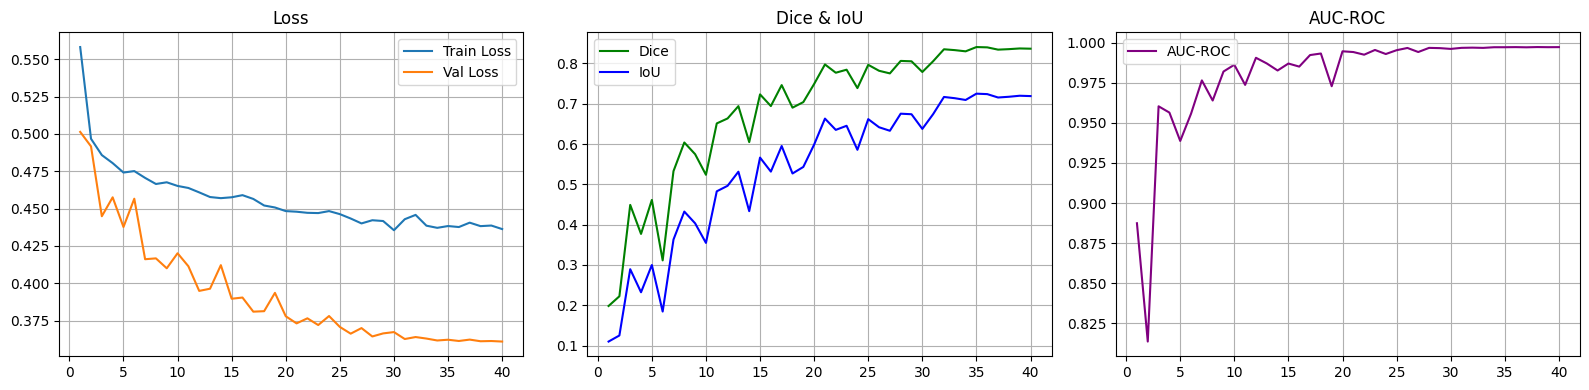

Training curves saved!


In [17]:
#Cell 10 — Training Curves
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
e = range(1, EPOCHS+1)

axes[0].plot(e, history["train_loss"], label="Train Loss")
axes[0].plot(e, history["val_loss"],   label="Val Loss")
axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(True)

axes[1].plot(e, history["val_dice"], label="Dice", color="green")
axes[1].plot(e, history["val_iou"],  label="IoU",  color="blue")
axes[1].set_title("Dice & IoU"); axes[1].legend(); axes[1].grid(True)

axes[2].plot(e, history["val_auc"], label="AUC-ROC", color="purple")
axes[2].set_title("AUC-ROC"); axes[2].legend(); axes[2].grid(True)

plt.tight_layout()
plt.savefig("/content/outputs/training_curves.png", dpi=150)
plt.show()
print("Training curves saved!")

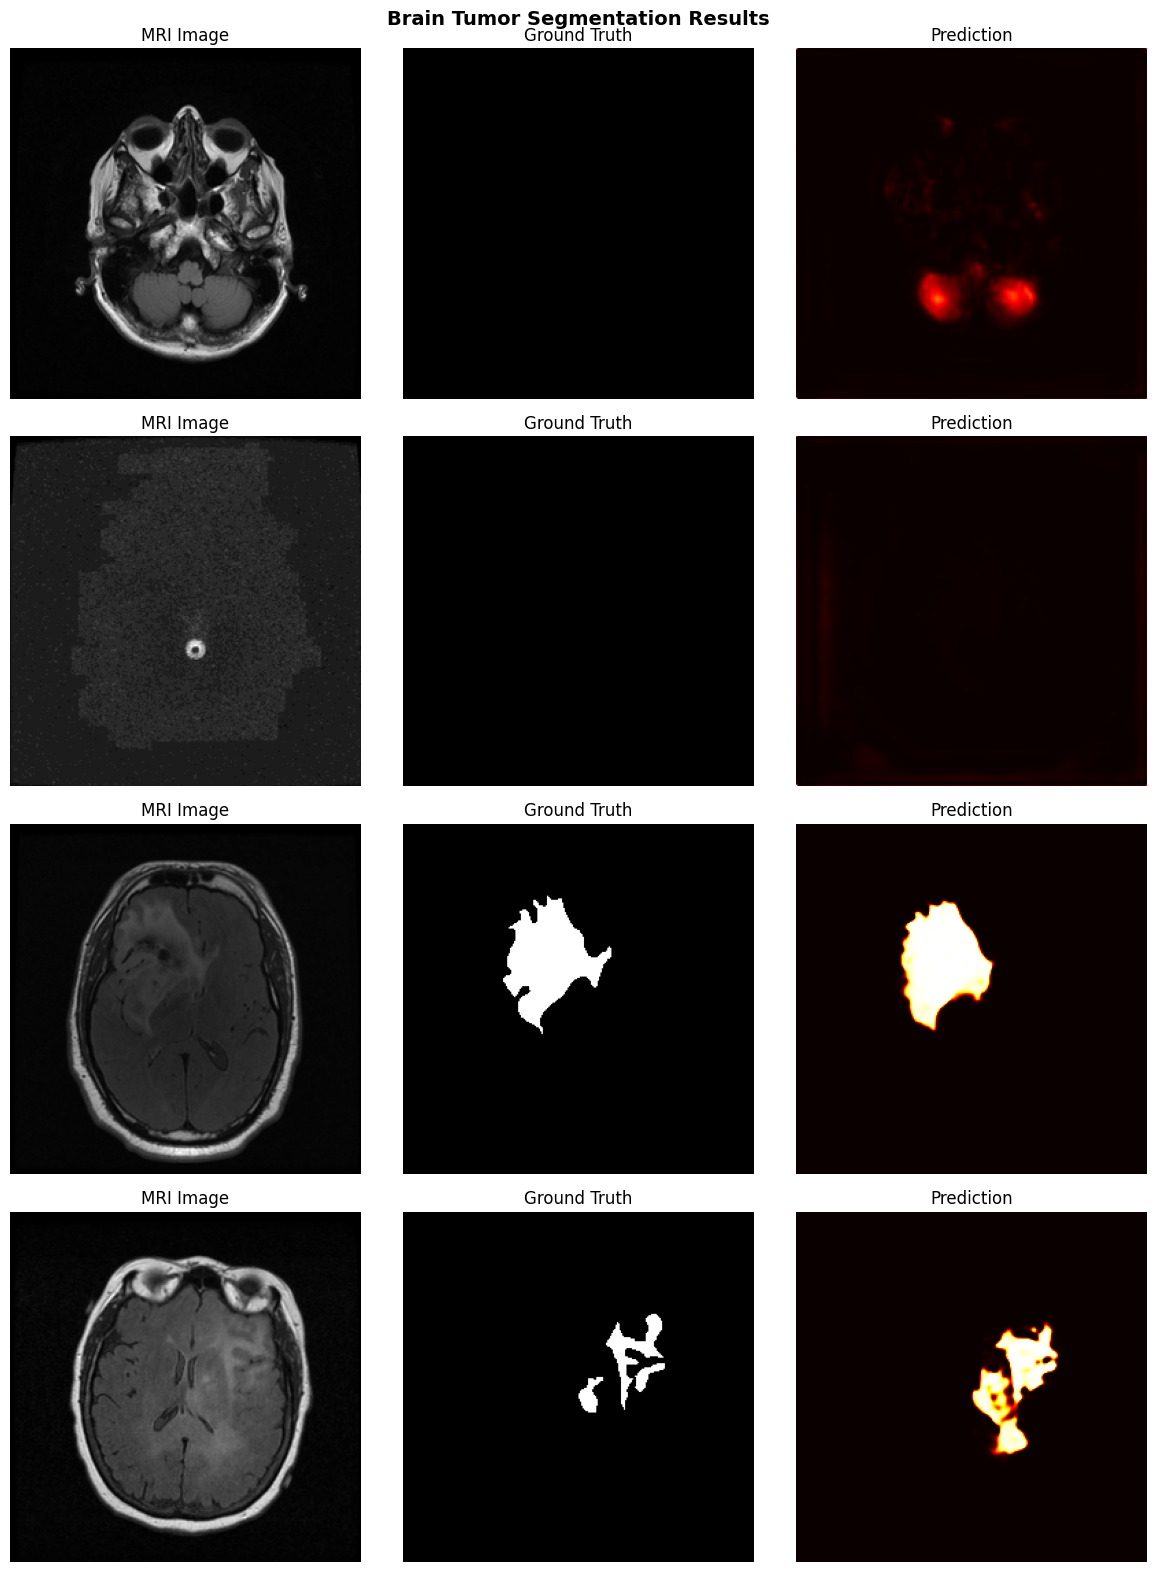

Predictions saved!


In [18]:
#Cell 11 — Visualise Predictions
model.eval()
fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for i in range(4):
    img_t, mask_t = test_ds[i]
    with torch.no_grad():
        pred = torch.sigmoid(model(img_t.unsqueeze(0).to(DEVICE)))
        pred = pred.squeeze().cpu().numpy()

    img_np  = img_t.squeeze().numpy()
    mask_np = mask_t.squeeze().numpy()

    axes[i,0].imshow(img_np,  cmap="gray")
    axes[i,0].set_title("MRI Image")
    axes[i,1].imshow(mask_np, cmap="gray")
    axes[i,1].set_title("Ground Truth")
    axes[i,2].imshow(pred,    cmap="hot")
    axes[i,2].set_title("Prediction")
    for j in range(3): axes[i,j].axis("off")

plt.suptitle("Brain Tumor Segmentation Results", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("/content/outputs/predictions.png", dpi=150)
plt.show()
print("Predictions saved!")

In [19]:
#Cell 12 — Save Outputs to Drive
import shutil
shutil.make_archive("/content/drive/MyDrive/BrainMRI_outputs", 'zip', "/content/outputs")
print("All outputs saved to your Google Drive!")

All outputs saved to your Google Drive!
